UK Road Safety Data -  Clustering
Performs clustering analysis to identify accident hotspots and their characteristics

steps:
1. Geographical Clustering
2. Pattern Analysis
3. Multi-dimensional Clustering
4. Predictive Model:
5. Risk Score: Create a risk score system for different areas.

methods:
* K-Means Clustering
* DBSCAN
* Hierarchical Clustering
* Feature-based clustering


Libraries and setup

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime

# Clustering libraries
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Model libraries
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Visualization
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Spatial libraries
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import dendrogram, linkage

# Configuration
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)

print("✓ Libraries imported successfully!")
print("\nNote: For map visualization, you may need:")
print("  pip install folium")

✓ Libraries imported successfully!

Note: For map visualization, you may need:
  pip install folium


Load Data

In [2]:
# Load collision data - UPDATE THESE PATHS
collisions_path = 'collisions.csv'

print("Loading collision data...")
try:
    df = pd.read_csv(collisions_path, low_memory=False)
    print(f"✓ Data loaded successfully!")
    print(f"Shape: {df.shape}")
    print(f"\nColumns: {df.columns.tolist()[:20]}...")
except FileNotFoundError:
    print("Error: File not found. Please update the file path.")

Loading collision data...
✓ Data loaded successfully!
Shape: (100927, 44)

Columns: ['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number']...


In [3]:
# Display sample data
print("Sample of collision data:")
display(df.head())

print("\nData types:")
display(df.dtypes)

Sample of collision data:


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,local_authority_highway_current,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202417M119024,2024,17M119024,450057,519938,-1.22722,54.57219,17,3,2,1,05/12/2024,5,16:10,-1,E06000002,E06000002,E06000002,6,0,6,30,-1,0,-1,-1,-1,-1,-1,0,4,2,2,-1,-1,0,1,3,2,E01035190,3,1,0.000000,1.000000
1,202417S312124,2024,17S312124,445858,516830,-1.29265,54.54466,17,3,1,1,22/10/2024,3,14:56,-1,E06000004,E06000004,E06000004,6,0,6,30,-1,0,-1,-1,-1,-1,-1,0,1,1,1,-1,-1,0,1,3,2,E01012239,3,1,0.000000,1.000000
2,2024070110901,2024,070110901,364765,390979,-2.53157,53.41443,7,3,2,1,24/01/2024,4,17:50,-1,E06000007,E06000007,E06000007,6,0,6,30,3,13,4,6,0,0,0,0,4,1,1,0,0,0,2,2,2,E01012459,-1,0,0.014743,0.985257
3,2024041446676,2024,041446676,365989,419804,-2.51630,53.67359,4,2,1,1,22/05/2024,4,17:45,-1,E06000008,E06000008,E06000008,3,675,6,50,-1,0,-1,-1,-1,-1,-1,0,1,5,5,-1,-1,0,2,1,2,E01012628,6,1,1.000000,0.000000
4,2024041478641,2024,041478641,366864,430071,-2.50416,53.76592,4,2,2,1,11/08/2024,1,15:36,-1,E06000008,E06000008,E06000008,3,6119,3,50,-1,16,4,6,0,-1,-1,0,1,1,1,-1,-1,0,1,1,2,E01012581,7,1,1.000000,0.000000



Data types:


collision_index                                      object
collision_year                                        int64
collision_ref_no                                     object
location_easting_osgr                                 int64
location_northing_osgr                                int64
longitude                                           float64
latitude                                            float64
police_force                                          int64
collision_severity                                    int64
number_of_vehicles                                    int64
number_of_casualties                                  int64
date                                                 object
day_of_week                                           int64
time                                                 object
local_authority_district                              int64
local_authority_ons_district                         object
local_authority_highway                 

Data Prepare and Feature Engineer

Identify using columns


In [4]:
# Identify important columns (common in DfT data)
# Location columns
lat_col = None
lon_col = None
for col in df.columns:
    if 'latitude' in col.lower():
        lat_col = col
    if 'longitude' in col.lower():
        lon_col = col

print(f"Location columns:")
print(f"  Latitude: {lat_col}")
print(f"  Longitude: {lon_col}")

# Time columns
date_col = None
time_col = None
for col in df.columns:
    if 'date' in col.lower() and date_col is None:
        date_col = col
    if 'time' in col.lower() and time_col is None:
        time_col = col

print(f"\nTime columns:")
print(f"  Date: {date_col}")
print(f"  Time: {time_col}")

# Other important columns
print(f"\nLooking for other important columns...")
important_patterns = ['severity', 'speed', 'road', 'light', 'weather', 'junction', 'urban']
found_cols = {}
for pattern in important_patterns:
    cols = [col for col in df.columns if pattern in col.lower()]
    if cols:
        found_cols[pattern] = cols[0]
        print(f"  {pattern}: {cols[0]}")

Location columns:
  Latitude: latitude
  Longitude: longitude

Time columns:
  Date: date
  Time: time

Looking for other important columns...
  severity: collision_severity
  speed: speed_limit
  road: first_road_class
  light: light_conditions
  weather: weather_conditions
  junction: junction_detail_historic
  urban: urban_or_rural_area


cleaning


In [5]:
# Create working dataframe
df_work = df.copy()

# Remove rows with missing location data
if lat_col and lon_col:
    print(f"Original shape: {df_work.shape}")
    df_work = df_work.dropna(subset=[lat_col, lon_col])
    print(f"After removing missing coordinates: {df_work.shape}")
    print(f"Removed {len(df) - len(df_work)} rows with missing location data")
    
    # Remove invalid coordinates (0,0 or obviously wrong)
    df_work = df_work[
        (df_work[lat_col] != 0) & 
        (df_work[lon_col] != 0) &
        (df_work[lat_col].between(49, 61)) &  # Valid UK latitude range
        (df_work[lon_col].between(-8, 2))      # Valid UK longitude range
    ]
    print(f"After removing invalid coordinates: {df_work.shape}")
else:
    print("⚠ Warning: Location columns not found. Geographic clustering will not be possible.")

Original shape: (100927, 44)
After removing missing coordinates: (100927, 44)
Removed 0 rows with missing location data
After removing invalid coordinates: (100927, 44)


In [6]:
# Process date and time
if date_col:
    df_work[date_col] = pd.to_datetime(df_work[date_col], errors='coerce')
    df_work['year'] = df_work[date_col].dt.year
    df_work['month'] = df_work[date_col].dt.month
    df_work['day'] = df_work[date_col].dt.day
    df_work['day_of_week'] = df_work[date_col].dt.dayofweek
    df_work['day_name'] = df_work[date_col].dt.day_name()
    df_work['is_weekend'] = (df_work['day_of_week'] >= 5).astype(int)
    print("✓ Date features created")

if time_col:
    # Convert time to hour (handle different formats)
    try:
        # If time is in HH:MM format
        df_work['hour'] = pd.to_datetime(df_work[time_col], format='%H:%M', errors='coerce').dt.hour
    except:
        try:
            # If time is in HHMM format
            df_work['hour'] = df_work[time_col].astype(str).str[:2].astype(float)
        except:
            print("⚠ Could not parse time column")
    
    if 'hour' in df_work.columns:
        # Create time periods
        df_work['time_period'] = pd.cut(df_work['hour'], 
                                         bins=[0, 6, 12, 18, 24],
                                         labels=['Night', 'Morning', 'Afternoon', 'Evening'],
                                         include_lowest=True)
        
        # Binary: is night time (10pm - 6am)
        df_work['is_night'] = ((df_work['hour'] >= 22) | (df_work['hour'] < 6)).astype(int)
        print("✓ Time features created")

✓ Date features created
✓ Time features created


In [7]:
# Display data summary
print("\n" + "="*60)
print("PROCESSED DATA SUMMARY")
print("="*60)
print(f"Total collisions: {len(df_work):,}")
if lat_col and lon_col:
    print(f"\nLocation range:")
    print(f"  Latitude: {df_work[lat_col].min():.4f} to {df_work[lat_col].max():.4f}")
    print(f"  Longitude: {df_work[lon_col].min():.4f} to {df_work[lon_col].max():.4f}")

print(f"\nNew features created:")
new_features = ['year', 'month', 'day', 'day_of_week', 'is_weekend', 'hour', 'time_period', 'is_night']
for feat in new_features:
    if feat in df_work.columns:
        print(f"  ✓ {feat}")


PROCESSED DATA SUMMARY
Total collisions: 100,927

Location range:
  Latitude: 49.9122 to 60.3448
  Longitude: -7.3887 to 1.7562

New features created:
  ✓ year
  ✓ month
  ✓ day
  ✓ day_of_week
  ✓ is_weekend
  ✓ hour
  ✓ time_period
  ✓ is_night


Analysis

Geographic Distribution

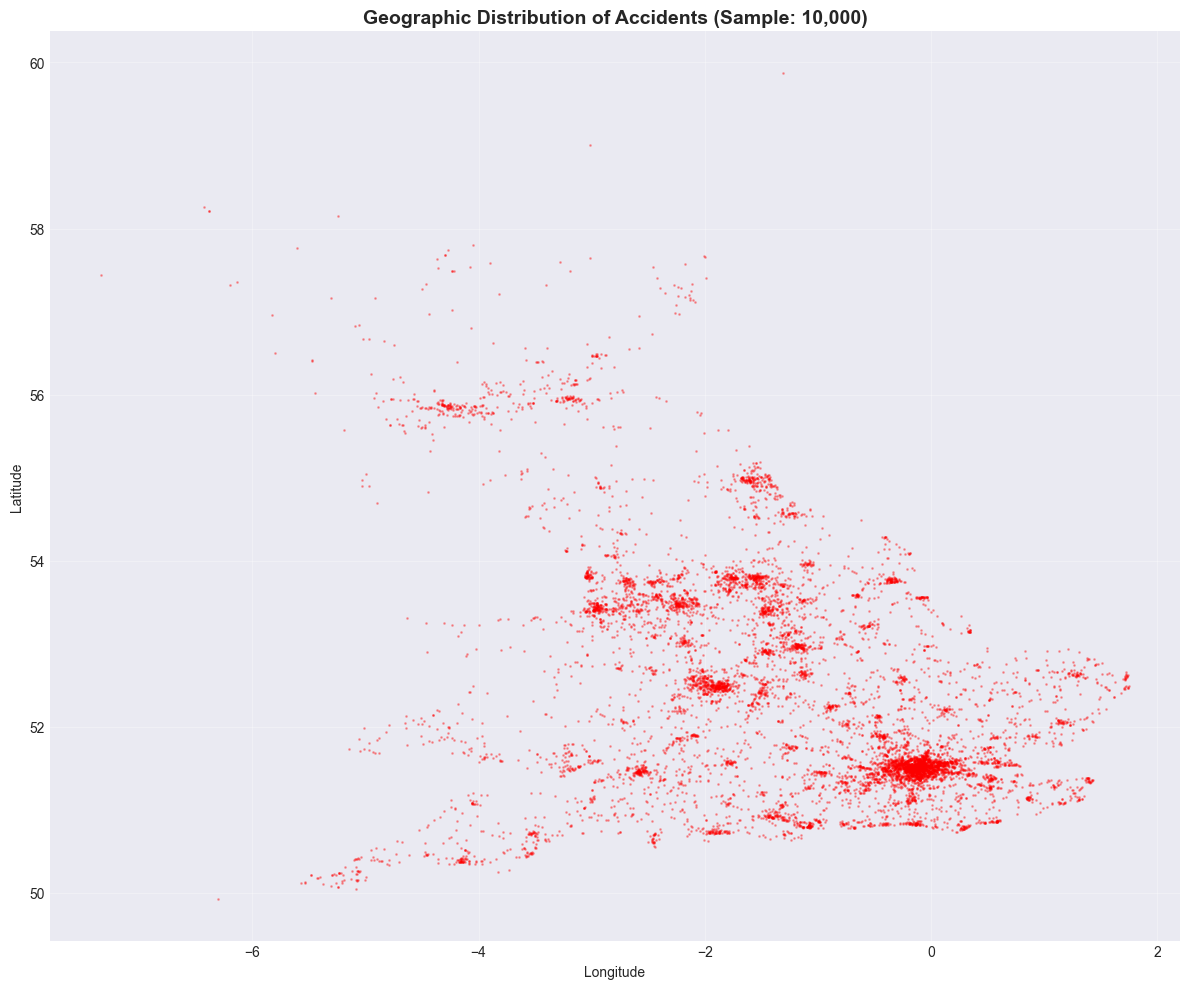

In [10]:
if lat_col and lon_col:
    # Basic scatter plot of all accidents
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Sample data if too large (for visualization performance)
    sample_size = min(10000, len(df_work))
    df_sample = df_work.sample(n=sample_size, random_state=42)
    
    ax.scatter(df_sample[lon_col], df_sample[lat_col], 
               alpha=0.3, s=1, c='red')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(f'Geographic Distribution of Accidents (Sample: {sample_size:,})', 
                 fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

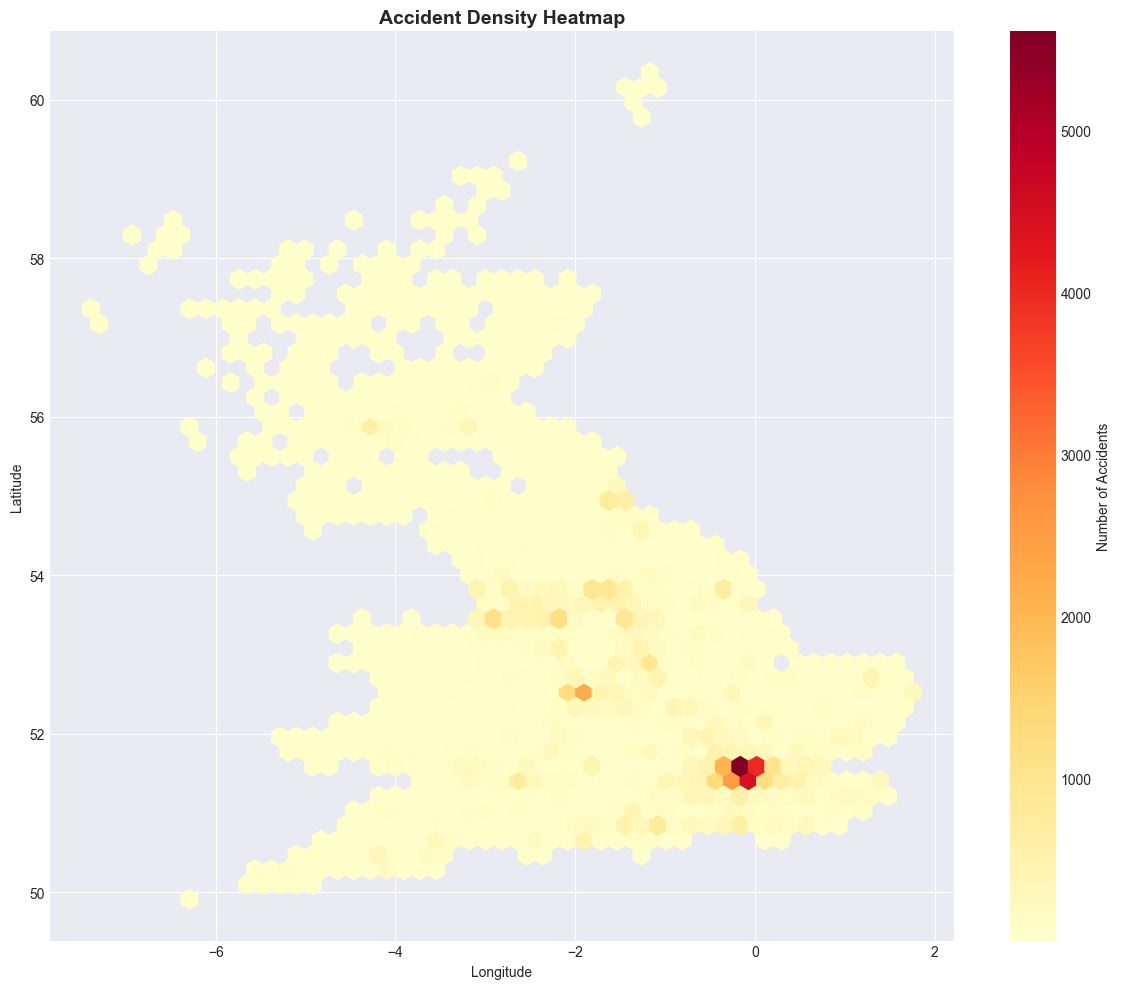

In [11]:
# Hexbin plot for density visualization
if lat_col and lon_col:
    fig, ax = plt.subplots(figsize=(12, 10))
    
    hexbin = ax.hexbin(df_work[lon_col], df_work[lat_col], 
                       gridsize=50, cmap='YlOrRd', mincnt=1)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title('Accident Density Heatmap', fontsize=14, fontweight='bold')
    plt.colorbar(hexbin, ax=ax, label='Number of Accidents')
    plt.tight_layout()
    plt.show()

Temporal Patterns

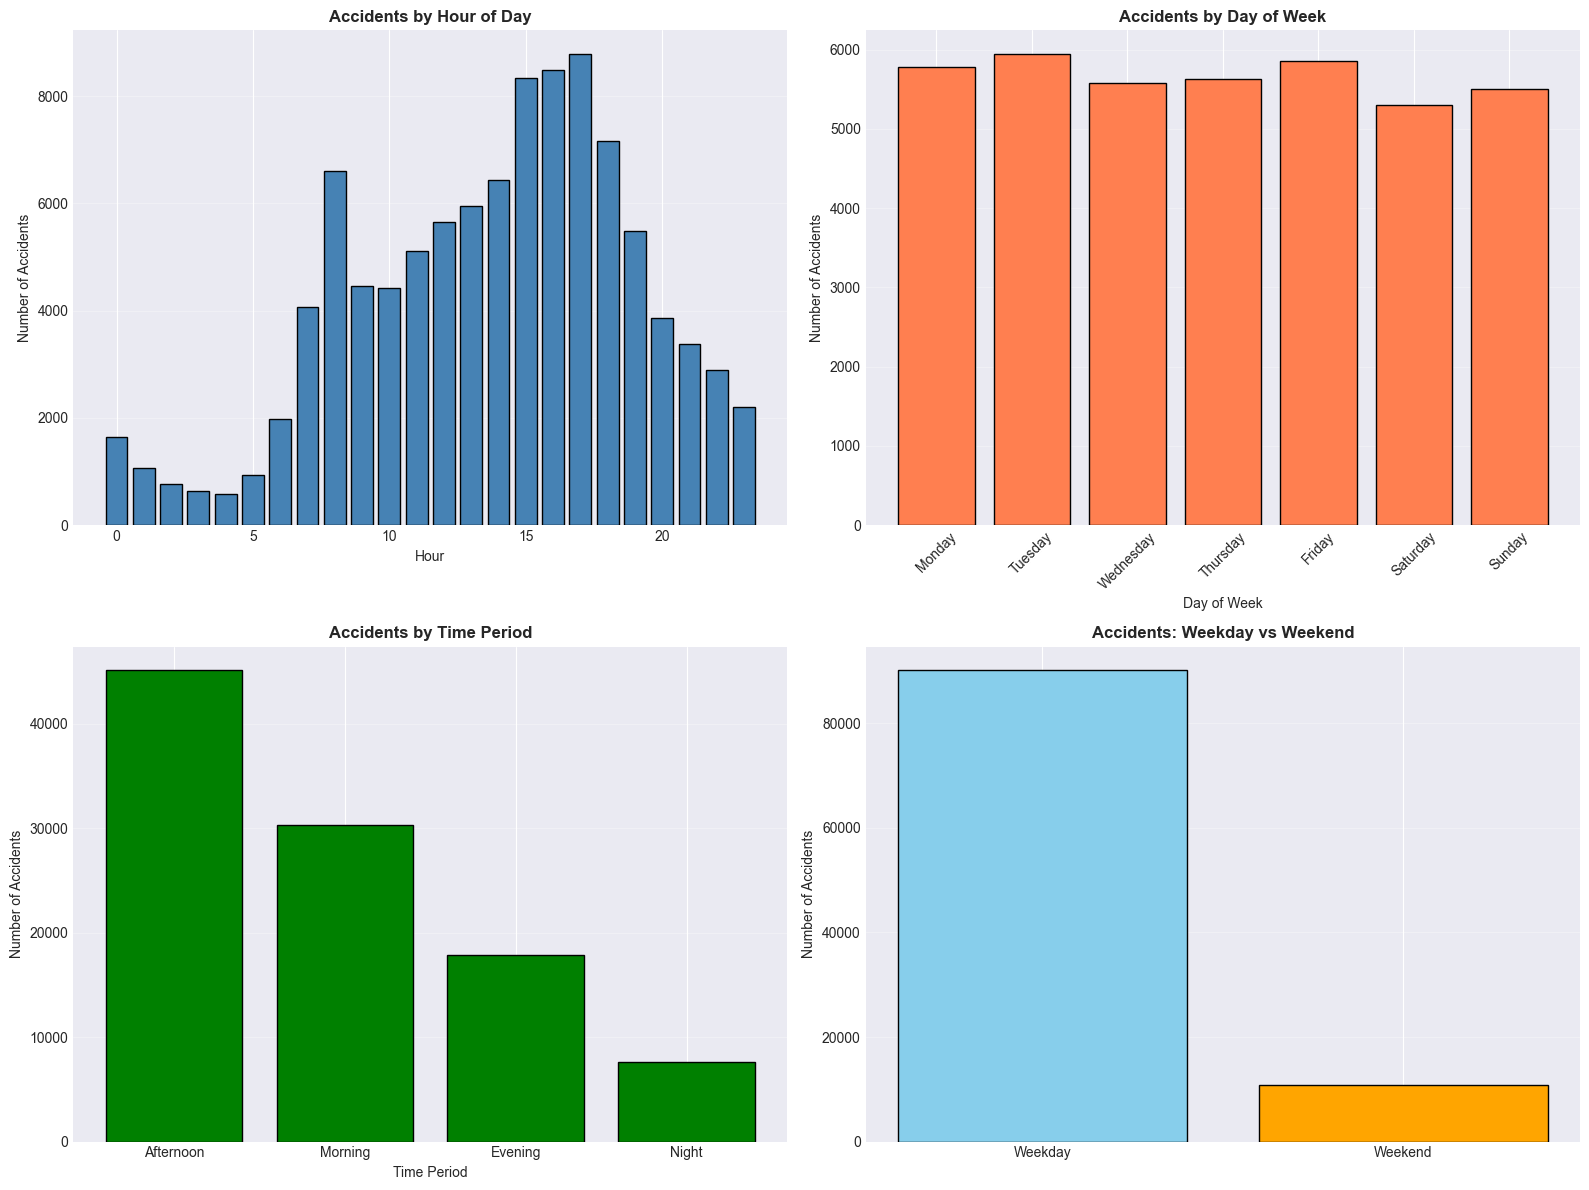

In [12]:
# Analyze time patterns
if 'hour' in df_work.columns:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Hourly distribution
    hour_counts = df_work['hour'].value_counts().sort_index()
    axes[0, 0].bar(hour_counts.index, hour_counts.values, color='steelblue', edgecolor='black')
    axes[0, 0].set_title('Accidents by Hour of Day', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Hour')
    axes[0, 0].set_ylabel('Number of Accidents')
    axes[0, 0].grid(axis='y', alpha=0.3)
    
    # Day of week
    day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    day_counts = df_work['day_of_week'].value_counts().sort_index()
    axes[0, 1].bar(range(7), day_counts.values, color='coral', edgecolor='black')
    axes[0, 1].set_title('Accidents by Day of Week', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Day of Week')
    axes[0, 1].set_ylabel('Number of Accidents')
    axes[0, 1].set_xticks(range(7))
    axes[0, 1].set_xticklabels(day_names, rotation=45)
    axes[0, 1].grid(axis='y', alpha=0.3)
    
    # Time period distribution
    if 'time_period' in df_work.columns:
        period_counts = df_work['time_period'].value_counts()
        axes[1, 0].bar(period_counts.index, period_counts.values, color='green', edgecolor='black')
        axes[1, 0].set_title('Accidents by Time Period', fontsize=12, fontweight='bold')
        axes[1, 0].set_xlabel('Time Period')
        axes[1, 0].set_ylabel('Number of Accidents')
        axes[1, 0].grid(axis='y', alpha=0.3)
    
    # Weekend vs Weekday
    if 'is_weekend' in df_work.columns:
        weekend_counts = df_work['is_weekend'].value_counts()
        axes[1, 1].bar(['Weekday', 'Weekend'], 
                       [weekend_counts.get(0, 0), weekend_counts.get(1, 0)],
                       color=['skyblue', 'orange'], edgecolor='black')
        axes[1, 1].set_title('Accidents: Weekday vs Weekend', fontsize=12, fontweight='bold')
        axes[1, 1].set_ylabel('Number of Accidents')
        axes[1, 1].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

Context Features Analysis

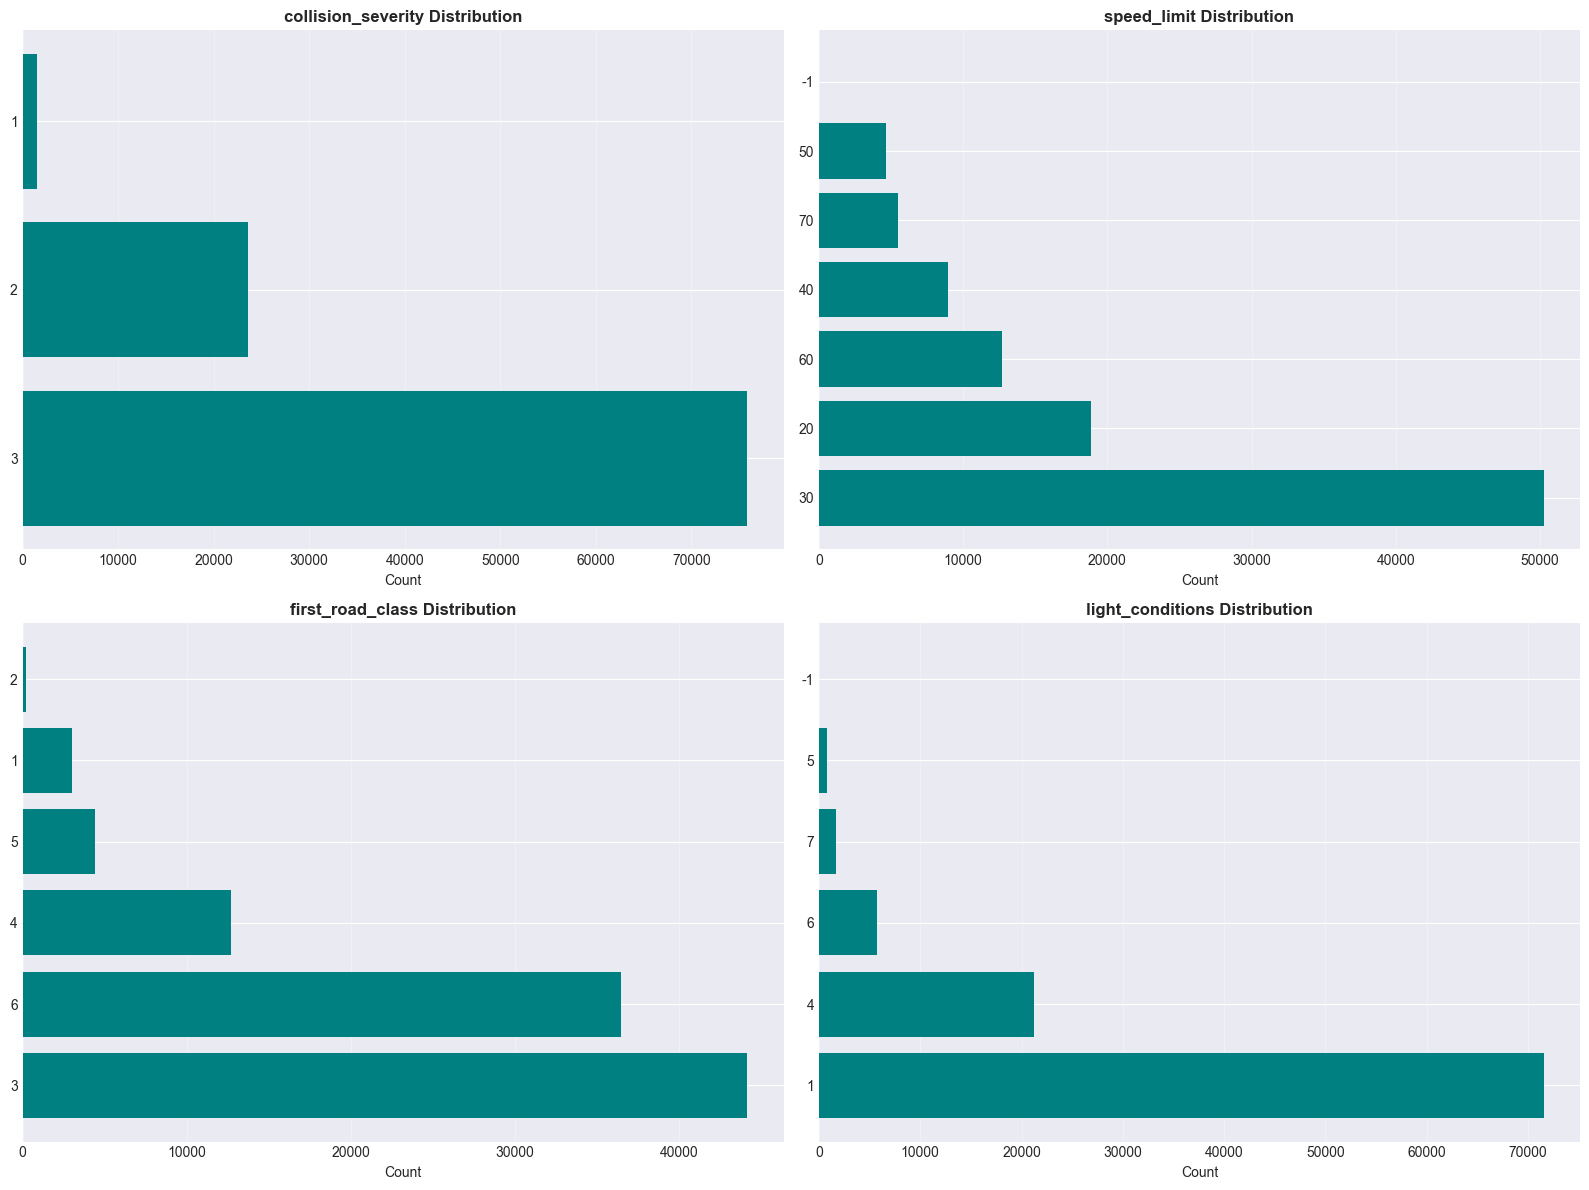

In [13]:
# Analyze categorical features
categorical_cols = []
for pattern in ['severity', 'speed', 'road', 'light', 'weather', 'junction']:
    if pattern in found_cols:
        categorical_cols.append(found_cols[pattern])

if len(categorical_cols) >= 4:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    for idx, col in enumerate(categorical_cols[:4]):
        top_values = df_work[col].value_counts().head(10)
        axes[idx].barh(range(len(top_values)), top_values.values, color='teal')
        axes[idx].set_yticks(range(len(top_values)))
        axes[idx].set_yticklabels(top_values.index)
        axes[idx].set_title(f'{col} Distribution', fontsize=12, fontweight='bold')
        axes[idx].set_xlabel('Count')
        axes[idx].grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

K-Means Clustering:Geographical

Determine Optinam Number of Cluster

Location data prepared: (100927, 2)

Finding optimal number of clusters...
This may take a few minutes...

Using sample of 50,000 points for optimization
k=2: Inertia=51445.84, Silhouette=0.4830
k=3: Inertia=33917.80, Silhouette=0.4816
k=4: Inertia=22340.76, Silhouette=0.5472
k=5: Inertia=18580.65, Silhouette=0.4773
k=6: Inertia=15270.82, Silhouette=0.4763
k=7: Inertia=12871.91, Silhouette=0.4953
k=8: Inertia=10789.91, Silhouette=0.4777
k=9: Inertia=9543.05, Silhouette=0.4637
k=10: Inertia=8510.87, Silhouette=0.4778
k=11: Inertia=7562.55, Silhouette=0.4894
k=12: Inertia=7000.99, Silhouette=0.4936
k=13: Inertia=6522.97, Silhouette=0.4698
k=14: Inertia=6059.77, Silhouette=0.4689
k=15: Inertia=5495.86, Silhouette=0.4740
k=16: Inertia=5105.81, Silhouette=0.4690
k=17: Inertia=4832.22, Silhouette=0.4521
k=18: Inertia=4541.15, Silhouette=0.4419
k=19: Inertia=4342.53, Silhouette=0.4417
k=20: Inertia=4060.81, Silhouette=0.4576


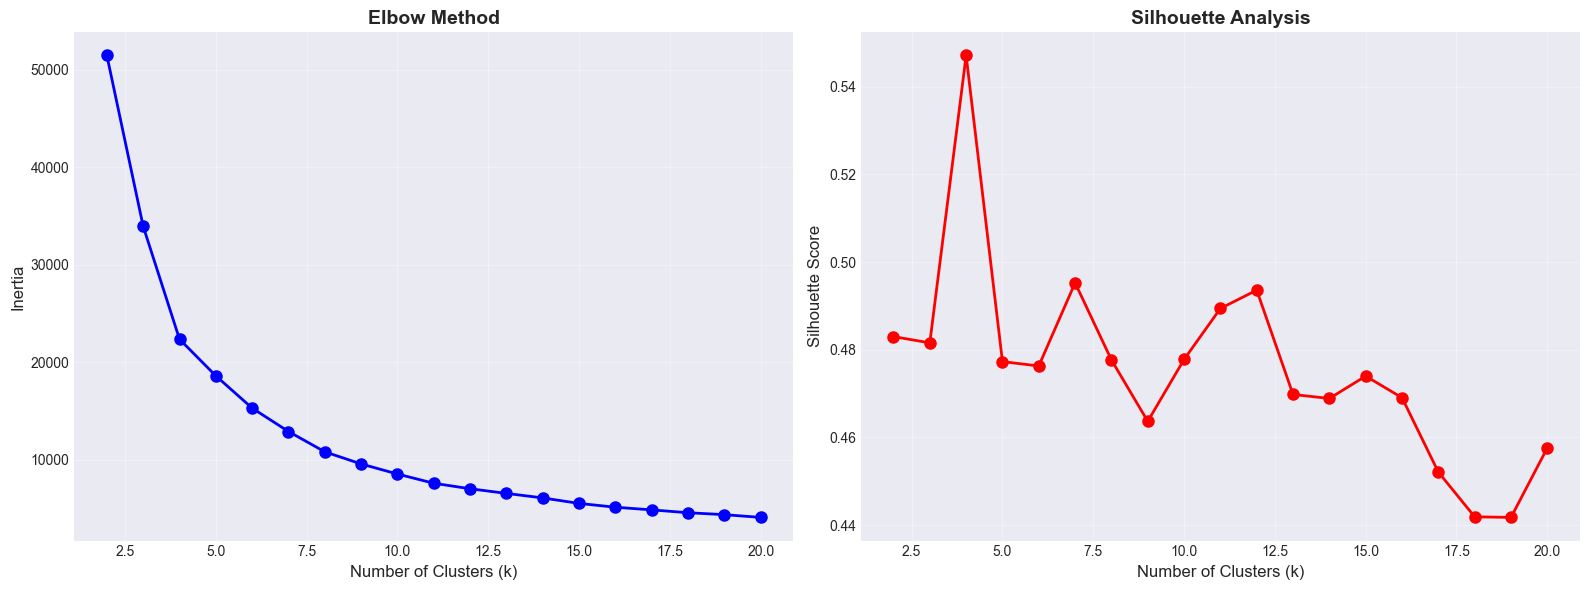


✓ Suggested optimal k (highest silhouette): 4

Note: Also consider the 'elbow' point in the inertia plot.


In [14]:
if lat_col and lon_col:
    # Prepare location data
    X_location = df_work[[lat_col, lon_col]].values
    
    # Standardize coordinates
    scaler_location = StandardScaler()
    X_location_scaled = scaler_location.fit_transform(X_location)
    
    print(f"Location data prepared: {X_location_scaled.shape}")
    print("\nFinding optimal number of clusters...")
    print("This may take a few minutes...\n")
    
    # Elbow method
    inertias = []
    silhouette_scores = []
    K_range = range(2, 21)
    
    # Sample data if too large (for computational efficiency)
    if len(X_location_scaled) > 50000:
        sample_indices = np.random.choice(len(X_location_scaled), 50000, replace=False)
        X_sample = X_location_scaled[sample_indices]
        print(f"Using sample of {len(X_sample):,} points for optimization")
    else:
        X_sample = X_location_scaled
    
    for k in K_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X_sample)
        inertias.append(kmeans.inertia_)
        silhouette_scores.append(silhouette_score(X_sample, kmeans.labels_, sample_size=10000))
        print(f"k={k}: Inertia={kmeans.inertia_:.2f}, Silhouette={silhouette_scores[-1]:.4f}")
    
    # Plot elbow curve and silhouette scores
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Elbow curve
    axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
    axes[0].set_xlabel('Number of Clusters (k)', fontsize=12)
    axes[0].set_ylabel('Inertia', fontsize=12)
    axes[0].set_title('Elbow Method', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    
    # Silhouette scores
    axes[1].plot(K_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
    axes[1].set_xlabel('Number of Clusters (k)', fontsize=12)
    axes[1].set_ylabel('Silhouette Score', fontsize=12)
    axes[1].set_title('Silhouette Analysis', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Suggest optimal k
    optimal_k_silhouette = K_range[np.argmax(silhouette_scores)]
    print(f"\n✓ Suggested optimal k (highest silhouette): {optimal_k_silhouette}")
    print(f"\nNote: Also consider the 'elbow' point in the inertia plot.")

Apply K-Means

In [15]:
if lat_col and lon_col:
    # Choose number of clusters (adjust based on elbow curve)
    n_clusters = 10  # You can change this based on the plots above
    
    print(f"Applying K-Means with {n_clusters} clusters...")
    
    # Fit K-Means on full dataset
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    df_work['cluster'] = kmeans.fit_predict(X_location_scaled)
    
    # Get cluster centers (in original scale)
    cluster_centers = scaler_location.inverse_transform(kmeans.cluster_centers_)
    
    print("✓ Clustering complete!")
    print(f"\nCluster sizes:")
    cluster_sizes = df_work['cluster'].value_counts().sort_index()
    for cluster_id, size in cluster_sizes.items():
        print(f"  Cluster {cluster_id}: {size:,} accidents ({size/len(df_work)*100:.1f}%)")
    
    # Calculate metrics
    silhouette = silhouette_score(X_location_scaled, df_work['cluster'], sample_size=10000)
    calinski = calinski_harabasz_score(X_location_scaled, df_work['cluster'])
    davies_bouldin = davies_bouldin_score(X_location_scaled, df_work['cluster'])
    
    print(f"\nClustering Quality Metrics:")
    print(f"  Silhouette Score: {silhouette:.4f} (higher is better, range: -1 to 1)")
    print(f"  Calinski-Harabasz Index: {calinski:.2f} (higher is better)")
    print(f"  Davies-Bouldin Index: {davies_bouldin:.4f} (lower is better)")

Applying K-Means with 10 clusters...
✓ Clustering complete!

Cluster sizes:
  Cluster 0: 4,199 accidents (4.2%)
  Cluster 1: 10,504 accidents (10.4%)
  Cluster 2: 5,884 accidents (5.8%)
  Cluster 3: 10,745 accidents (10.6%)
  Cluster 4: 33,730 accidents (33.4%)
  Cluster 5: 3,636 accidents (3.6%)
  Cluster 6: 9,961 accidents (9.9%)
  Cluster 7: 8,706 accidents (8.6%)
  Cluster 8: 6,330 accidents (6.3%)
  Cluster 9: 7,232 accidents (7.2%)

Clustering Quality Metrics:
  Silhouette Score: 0.4718 (higher is better, range: -1 to 1)
  Calinski-Harabasz Index: 122537.54 (higher is better)
  Davies-Bouldin Index: 0.7696 (lower is better)


Visualize geographic clusters

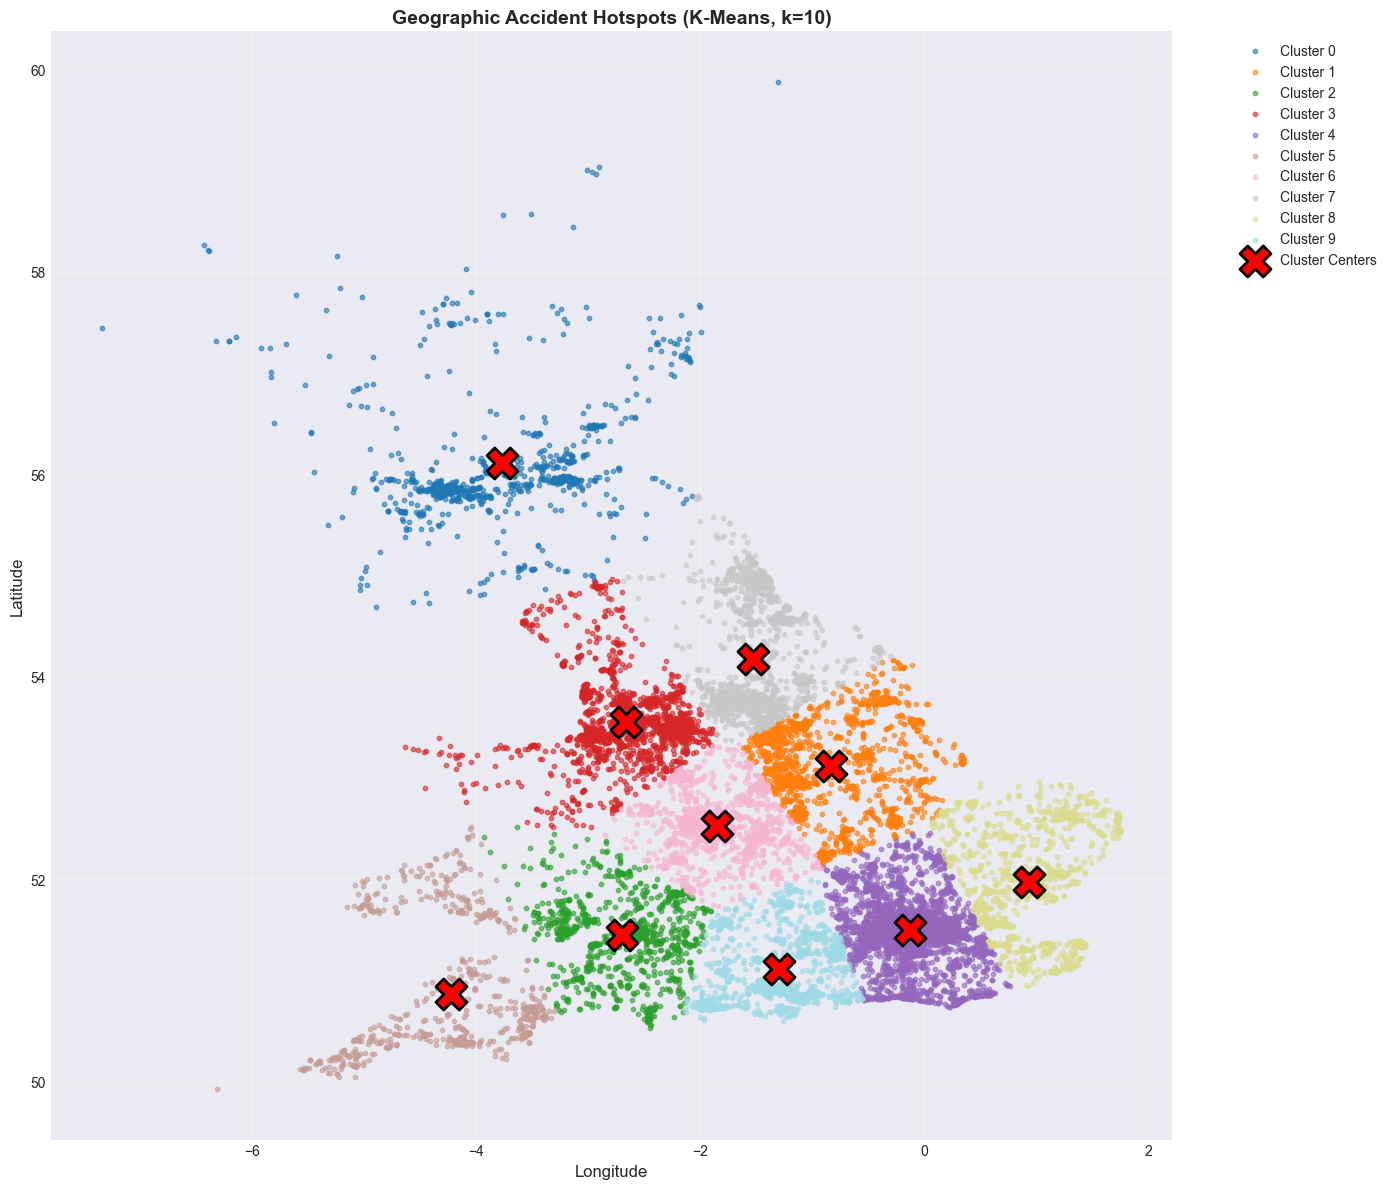

In [16]:
if lat_col and lon_col and 'cluster' in df_work.columns:
    # Create color map
    colors = plt.cm.tab20(np.linspace(0, 1, n_clusters))
    
    fig, ax = plt.subplots(figsize=(14, 12))
    
    # Sample for visualization
    sample_size = min(20000, len(df_work))
    df_plot = df_work.sample(n=sample_size, random_state=42)
    
    # Plot each cluster
    for cluster_id in range(n_clusters):
        cluster_data = df_plot[df_plot['cluster'] == cluster_id]
        ax.scatter(cluster_data[lon_col], cluster_data[lat_col],
                  c=[colors[cluster_id]], label=f'Cluster {cluster_id}',
                  alpha=0.6, s=10)
    
    # Plot cluster centers
    ax.scatter(cluster_centers[:, 1], cluster_centers[:, 0],
              c='red', marker='X', s=500, edgecolors='black', linewidths=2,
              label='Cluster Centers', zorder=5)
    
    # Add cluster labels
    for i, center in enumerate(cluster_centers):
        ax.annotate(f'C{i}', xy=(center[1], center[0]), 
                   fontsize=12, fontweight='bold', ha='center', va='center')
    
    ax.set_xlabel('Longitude', fontsize=12)
    ax.set_ylabel('Latitude', fontsize=12)
    ax.set_title(f'Geographic Accident Hotspots (K-Means, k={n_clusters})', 
                fontsize=14, fontweight='bold')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [17]:
# Interactive plot with Plotly
if lat_col and lon_col and 'cluster' in df_work.columns:
    # Sample for interactive plot
    sample_size = min(15000, len(df_work))
    df_interactive = df_work.sample(n=sample_size, random_state=42)
    
    fig = px.scatter_mapbox(
        df_interactive,
        lat=lat_col,
        lon=lon_col,
        color='cluster',
        hover_data=['cluster'],
        zoom=5,
        title=f'Interactive Accident Hotspot Map (Sample: {sample_size:,})',
        height=700
    )
    
    fig.update_layout(mapbox_style="open-street-map")
    fig.show()

Hotspot Characterization

Analyze each's cluster characteristics

In [18]:
# Analyze characteristics of each cluster
if 'cluster' in df_work.columns:
    print("="*80)
    print("HOTSPOT CHARACTERISTICS ANALYSIS")
    print("="*80)
    
    for cluster_id in range(n_clusters):
        cluster_data = df_work[df_work['cluster'] == cluster_id]
        
        print(f"\n{'='*80}")
        print(f"CLUSTER {cluster_id} (Hotspot {cluster_id + 1})")
        print(f"{'='*80}")
        print(f"Total accidents: {len(cluster_data):,} ({len(cluster_data)/len(df_work)*100:.1f}% of total)")
        
        if lat_col and lon_col:
            print(f"\nLocation:")
            print(f"  Center: ({cluster_centers[cluster_id][0]:.4f}, {cluster_centers[cluster_id][1]:.4f})")
            print(f"  Lat range: {cluster_data[lat_col].min():.4f} to {cluster_data[lat_col].max():.4f}")
            print(f"  Lon range: {cluster_data[lon_col].min():.4f} to {cluster_data[lon_col].max():.4f}")
        
        # Time patterns
        if 'hour' in cluster_data.columns:
            peak_hour = cluster_data['hour'].mode().values[0] if len(cluster_data['hour'].mode()) > 0 else 'N/A'
            avg_hour = cluster_data['hour'].mean()
            print(f"\nTime Patterns:")
            print(f"  Peak hour: {peak_hour}:00")
            print(f"  Average hour: {avg_hour:.1f}:00")
        
        if 'is_night' in cluster_data.columns:
            night_pct = cluster_data['is_night'].mean() * 100
            print(f"  Night-time accidents: {night_pct:.1f}%")
        
        if 'is_weekend' in cluster_data.columns:
            weekend_pct = cluster_data['is_weekend'].mean() * 100
            print(f"  Weekend accidents: {weekend_pct:.1f}%")
        
        # Categorical features
        for pattern in ['severity', 'speed', 'light', 'weather']:
            if pattern in found_cols:
                col = found_cols[pattern]
                if col in cluster_data.columns:
                    top_value = cluster_data[col].mode().values[0] if len(cluster_data[col].mode()) > 0 else 'N/A'
                    top_count = cluster_data[col].value_counts().iloc[0] if len(cluster_data[col].value_counts()) > 0 else 0
                    top_pct = (top_count / len(cluster_data) * 100) if len(cluster_data) > 0 else 0
                    print(f"\n{pattern.capitalize()}:")
                    print(f"  Most common: {top_value} ({top_pct:.1f}%)")

HOTSPOT CHARACTERISTICS ANALYSIS

CLUSTER 0 (Hotspot 1)
Total accidents: 4,199 (4.2% of total)

Location:
  Center: (56.1141, -3.7686)
  Lat range: 54.6801 to 60.3448
  Lon range: -7.3887 to -1.1541

Time Patterns:
  Peak hour: 16:00
  Average hour: 13.9:00
  Night-time accidents: 9.5%
  Weekend accidents: 11.2%

Severity:
  Most common: 3 (56.2%)

Speed:
  Most common: 30 (44.1%)

Light:
  Most common: 1 (71.0%)

Weather:
  Most common: 1 (77.1%)

CLUSTER 1 (Hotspot 2)
Total accidents: 10,504 (10.4% of total)

Location:
  Center: (53.1154, -0.8296)
  Lat range: 52.1405 to 54.1771
  Lon range: -1.6251 to 0.3502

Time Patterns:
  Peak hour: 16:00
  Average hour: 13.7:00
  Night-time accidents: 9.9%
  Weekend accidents: 10.8%

Severity:
  Most common: 3 (74.6%)

Speed:
  Most common: 30 (57.6%)

Light:
  Most common: 1 (71.4%)

Weather:
  Most common: 1 (78.3%)

CLUSTER 2 (Hotspot 3)
Total accidents: 5,884 (5.8% of total)

Location:
  Center: (51.4466, -2.6969)
  Lat range: 50.5156 to 52

Compare cluster features

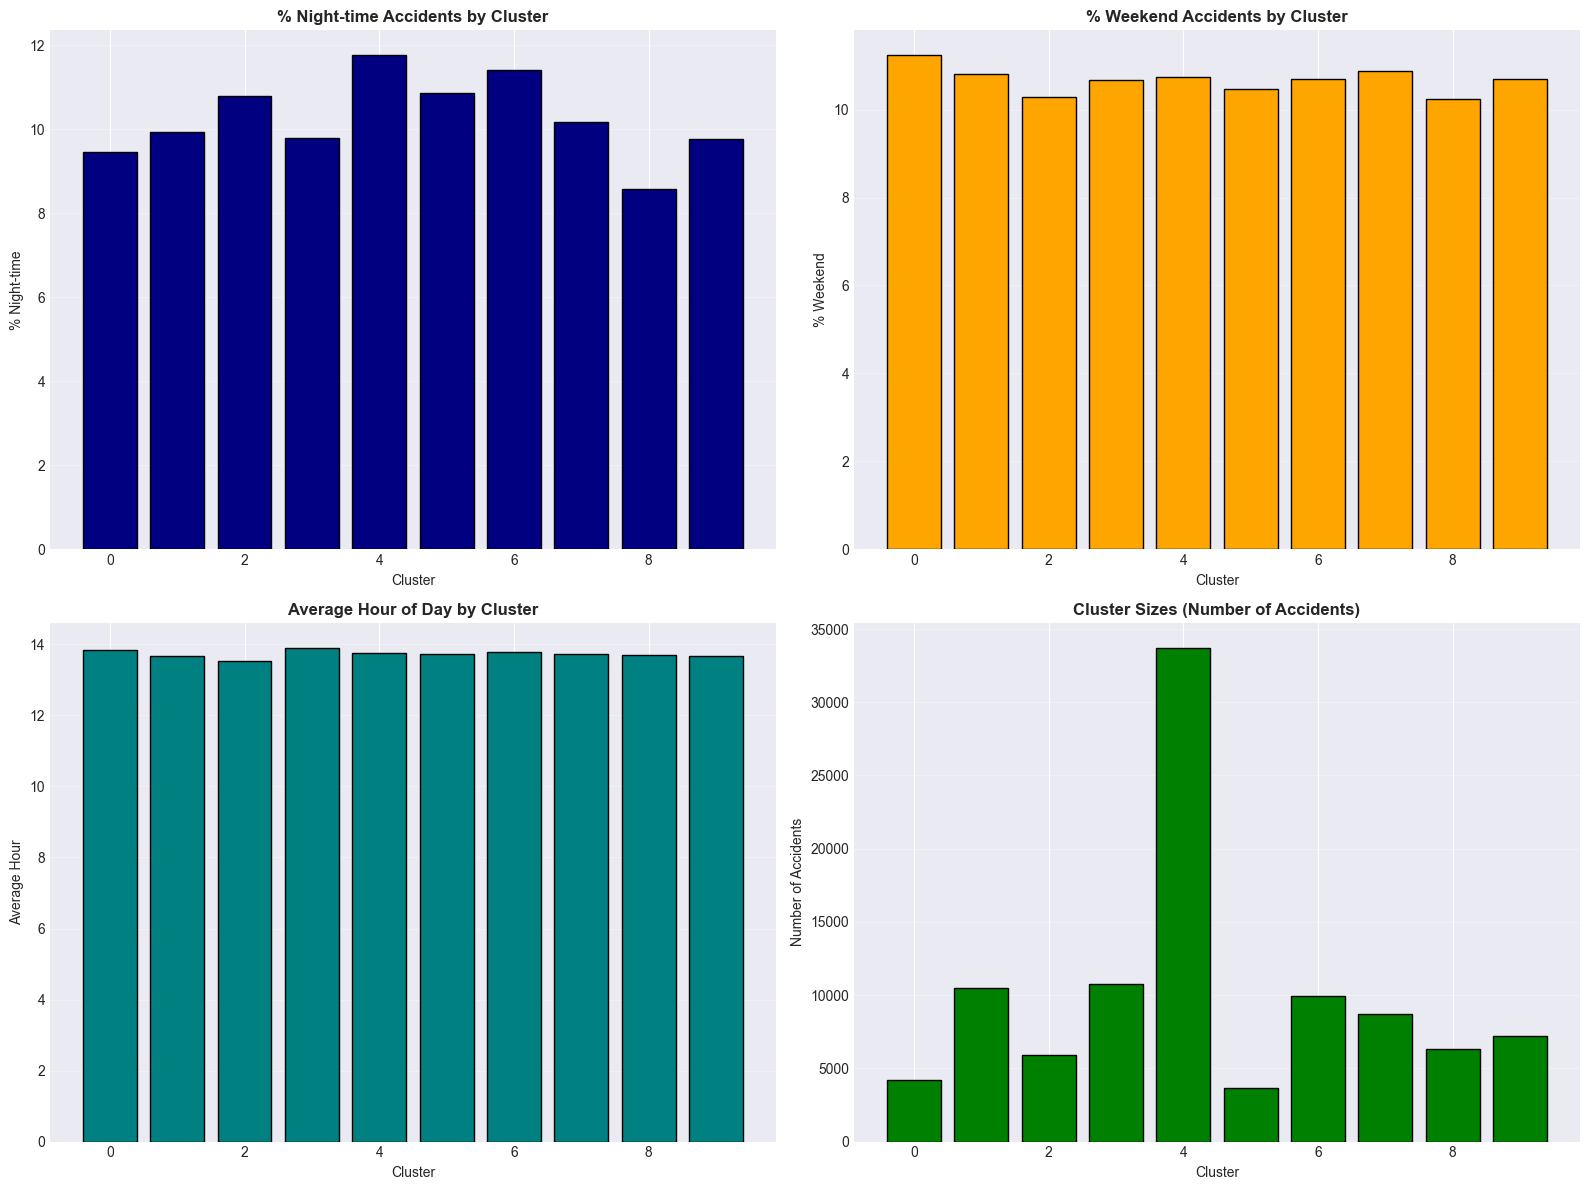

In [19]:
# Create comparison visualizations
if 'cluster' in df_work.columns:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Night-time accidents by cluster
    if 'is_night' in df_work.columns:
        night_by_cluster = df_work.groupby('cluster')['is_night'].mean() * 100
        axes[0, 0].bar(range(n_clusters), night_by_cluster.values, color='navy', edgecolor='black')
        axes[0, 0].set_title('% Night-time Accidents by Cluster', fontsize=12, fontweight='bold')
        axes[0, 0].set_xlabel('Cluster')
        axes[0, 0].set_ylabel('% Night-time')
        axes[0, 0].grid(axis='y', alpha=0.3)
    
    # Weekend accidents by cluster
    if 'is_weekend' in df_work.columns:
        weekend_by_cluster = df_work.groupby('cluster')['is_weekend'].mean() * 100
        axes[0, 1].bar(range(n_clusters), weekend_by_cluster.values, color='orange', edgecolor='black')
        axes[0, 1].set_title('% Weekend Accidents by Cluster', fontsize=12, fontweight='bold')
        axes[0, 1].set_xlabel('Cluster')
        axes[0, 1].set_ylabel('% Weekend')
        axes[0, 1].grid(axis='y', alpha=0.3)
    
    # Average hour by cluster
    if 'hour' in df_work.columns:
        hour_by_cluster = df_work.groupby('cluster')['hour'].mean()
        axes[1, 0].bar(range(n_clusters), hour_by_cluster.values, color='teal', edgecolor='black')
        axes[1, 0].set_title('Average Hour of Day by Cluster', fontsize=12, fontweight='bold')
        axes[1, 0].set_xlabel('Cluster')
        axes[1, 0].set_ylabel('Average Hour')
        axes[1, 0].grid(axis='y', alpha=0.3)
    
    # Cluster sizes
    cluster_sizes = df_work['cluster'].value_counts().sort_index()
    axes[1, 1].bar(range(n_clusters), cluster_sizes.values, color='green', edgecolor='black')
    axes[1, 1].set_title('Cluster Sizes (Number of Accidents)', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Cluster')
    axes[1, 1].set_ylabel('Number of Accidents')
    axes[1, 1].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

Identify High Risk Hotspot

In [20]:
# Create risk score for each cluster
if 'cluster' in df_work.columns:
    cluster_stats = pd.DataFrame()
    
    for cluster_id in range(n_clusters):
        cluster_data = df_work[df_work['cluster'] == cluster_id]
        
        stats = {
            'Cluster': cluster_id,
            'Num_Accidents': len(cluster_data),
            'Pct_of_Total': len(cluster_data) / len(df_work) * 100
        }
        
        if lat_col and lon_col:
            stats['Center_Lat'] = cluster_centers[cluster_id][0]
            stats['Center_Lon'] = cluster_centers[cluster_id][1]
        
        if 'is_night' in cluster_data.columns:
            stats['Night_Pct'] = cluster_data['is_night'].mean() * 100
        
        if 'is_weekend' in cluster_data.columns:
            stats['Weekend_Pct'] = cluster_data['is_weekend'].mean() * 100
        
        # Severity (if available)
        if 'severity' in found_cols:
            sev_col = found_cols['severity']
            if sev_col in cluster_data.columns:
                # Assuming lower severity number = more severe
                # Adjust this based on your data's encoding
                stats['Avg_Severity'] = pd.to_numeric(cluster_data[sev_col], errors='coerce').mean()
        
        cluster_stats = pd.concat([cluster_stats, pd.DataFrame([stats])], ignore_index=True)
    
    # Calculate risk score (weighted combination of factors)
    # Normalize factors to 0-1 range
    cluster_stats['Size_Score'] = cluster_stats['Num_Accidents'] / cluster_stats['Num_Accidents'].max()
    
    if 'Night_Pct' in cluster_stats.columns:
        cluster_stats['Night_Score'] = cluster_stats['Night_Pct'] / 100
    else:
        cluster_stats['Night_Score'] = 0
    
    # Calculate composite risk score
    cluster_stats['Risk_Score'] = (
        0.6 * cluster_stats['Size_Score'] +  # 60% weight on volume
        0.4 * cluster_stats['Night_Score']    # 40% weight on night-time
    )
    
    # Sort by risk score
    cluster_stats = cluster_stats.sort_values('Risk_Score', ascending=False)
    
    print("\n" + "="*80)
    print("HOTSPOT RISK RANKING")
    print("="*80)
    display(cluster_stats)
    
    # Identify top 3 high-risk hotspots
    top_3_clusters = cluster_stats.head(3)['Cluster'].values
    print(f"\n🔴 TOP 3 HIGH-RISK HOTSPOTS:")
    for rank, cluster_id in enumerate(top_3_clusters, 1):
        cluster_info = cluster_stats[cluster_stats['Cluster'] == cluster_id].iloc[0]
        print(f"\n  #{rank} - Cluster {int(cluster_id)}")
        print(f"       Risk Score: {cluster_info['Risk_Score']:.3f}")
        print(f"       Accidents: {int(cluster_info['Num_Accidents']):,}")
        if 'Center_Lat' in cluster_info:
            print(f"       Location: ({cluster_info['Center_Lat']:.4f}, {cluster_info['Center_Lon']:.4f})")


HOTSPOT RISK RANKING


,Cluster,Num_Accidents,Pct_of_Total,Center_Lat,Center_Lon,Night_Pct,Weekend_Pct,Avg_Severity,Size_Score,Night_Score,Risk_Score
4,4,33730,33.420195,51.491797,-0.127535,11.761044,10.741180,2.792114,1.000000,0.117610,0.647044
3,3,10745,10.646309,53.553845,-2.663612,9.781294,10.665426,2.682085,0.318559,0.097813,0.230261
1,1,10504,10.407522,53.115401,-0.829555,9.929551,10.805407,2.727532,0.311414,0.099296,0.226567
6,6,9961,9.869510,52.525746,-1.850291,11.414517,10.691698,2.733159,0.295316,0.114145,0.222848
7,7,8706,8.626037,54.174189,-1.531928,10.165403,10.877556,2.703997,0.258109,0.101654,0.195527
9,9,7232,7.165575,51.115687,-1.301305,9.775996,10.688606,2.752765,0.214409,0.097760,0.167749
2,2,5884,5.829956,51.446649,-2.696899,10.791978,10.299116,2.770224,0.174444,0.107920,0.147834
8,8,6330,6.271860,51.965769,0.932574,8.578199,10.236967,2.694787,0.187667,0.085782,0.146913
0,0,4199,4.160433,56.114108,-3.768591,9.454632,11.240772,2.525601,0.124489,0.094546,0.112512
5,5,3636,3.602604,50.859643,-4.218587,10.863586,10.478548,2.729923,0.107797,0.108636,0.108133



🔴 TOP 3 HIGH-RISK HOTSPOTS:

  #1 - Cluster 4
       Risk Score: 0.647
       Accidents: 33,730
       Location: (51.4918, -0.1275)

  #2 - Cluster 3
       Risk Score: 0.230
       Accidents: 10,745
       Location: (53.5538, -2.6636)

  #3 - Cluster 1
       Risk Score: 0.227
       Accidents: 10,504
       Location: (53.1154, -0.8296)
